# **Block 04 assignment**: *flux observations*

**Name**: Ben Löw

**Matriculation nr.**: 5737500

**Tower sets student id**: 39

**GitHub fork**: https://github.com/loew-b/datascience_env_monit

----------

## 0\) Data import

Importing required packages for data handling:

In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
import seaborn as sns
from pathlib import Path
import os

Setting project folder as working directory:

In [2]:
proj_dir = Path(os.getcwd()).parent

Sepcifying file locations, then importing `.csv` files:

In [ ]:
# ---- File locations ----
files = {
    'CA_Ca3': 'data/processed/AMF_CA-Ca3_FLUXNET_2001-2024_v1.3_r1/AMF_CA-Ca3_FLUXNET_FLUXMET_HH_2001-2024_v1.3_r1.csv',
    'US_Whs': 'data/processed/AMF_US-Whs_FLUXNET_2007-2025_v1.3_r1/AMF_US-Whs_FLUXNET_FLUXMET_HH_2007-2025_v1.3_r1.csv',
    'CN_Nmn': 'data/processed/CNF_CN-Nmn_FLUXNET_2015-2019_v1.3_r1/CNF_CN-Nmn_FLUXNET_FLUXMET_HH_2015-2019_v1.3_r1.csv',
    'FR_Pue': 'data/processed/ICOS_FR-Pue_FLUXNET_2000-2026_v1.3_r1/ICOS_FR-Pue_FLUXNET_FLUXMET_HH_2000-2026_v1.3_r1.csv',
    'AU_Rig': 'data/processed/TERN_AU-Rig_FLUXNET_2011-2017_v1.3_r1/TERN_AU-Rig_FLUXNET_FLUXMET_HH_2011-2017_v1.3_r1.csv'
}

# ---- Reading data from file locations ----
data = {}

for stn in files:
    data[stn] = pd.read_csv(
        proj_dir / files[stn],
        na_values=[-9999],
        dtype={"TIMESTAMP_START": str, "TIMESTAMP_END": str}
    )

data_df = pd.concat(data)

# ---- Convert timestamp to datetime format ----
data_df['TIME'] = pd.to_datetime(data_df['TIMESTAMP_START'], format="%Y%m%d%H%M")

data_df = data_df.set_index(data_df.index.get_level_values(0))
data_df['station'] = data_df.index

<positron-console-cell-4>:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-4>:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-4>:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`


----------

## 1\) Site overview

Loading metadata for the specific set of towers:

In [ ]:
# ---- Tower set metadata ----
student_no = 39

towers_meta = pd.read_csv(proj_dir / 'scripts/block04/tower_sets.csv')
towers_meta = towers_meta[towers_meta['student_no'] == 39]

Table with information about the five selected FluxNet sites:

In [11]:
meta_vars = ['site_id', 'site_name', 'igbp', 'lat', 'lon', 'first_year', 'last_year', 'citation']
print(towers_meta[meta_vars])

    site_id                                          site_name igbp       lat        lon  first_year  last_year  \
190  FR-Pue                                          Puechabon  EBF  43.74130    3.59570        2000       2026   
191  CA-Ca3  British Columbia - Pole sapling Douglas-fir stand  ENF  49.53460 -124.90040        2001       2024   
192  AU-Rig                                        Riggs Creek  GRA -36.64990  145.57590        2011       2017   
193  CN-Nmn                                             Naiman  CRO  42.94611  120.72694        2015       2019   
194  US-Whs                     Walnut Gulch Lucky Hills Shrub  OSH  31.74380 -110.05220        2007       2025   

                                              citation  
190  Joffre, R., Limousin, J., Kempf, J., Ourcival,...  
191  T. Andrew Black (2026), AmeriFlux FLUXNET-1F C...  
192  Beringer, J., McHugh, I. (2026): Riggs Creek F...  
193  Li, Y. (2026). Fluxnet Archive Product from Na...  
194  Russ Scott (2026), 

Map overview of site locations:

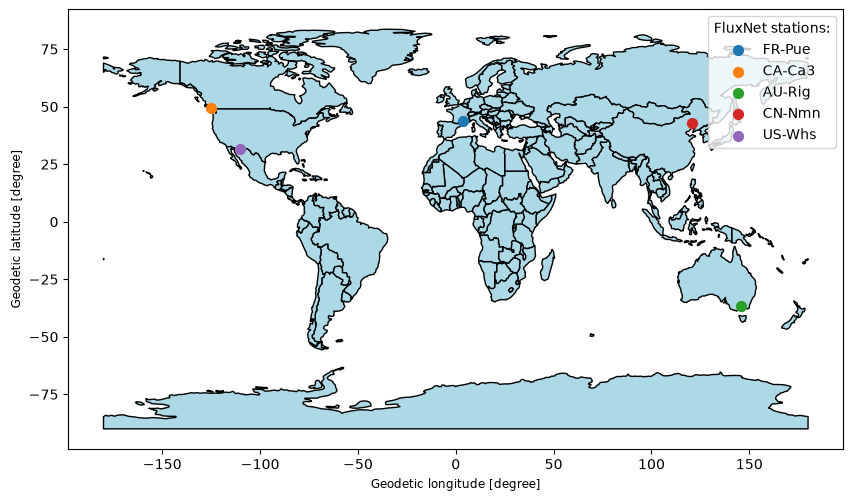

In [26]:
# ---- World map as background ----
world = gpd.read_file(proj_dir / 'data/processed/ne_110m_admin_0_countries/ne_110m_admin_0_countries.shp')
# Annotation: it was necessary to download a specific file for this from Natural Earth

fig, ax = plt.subplots(figsize=(10, 6))
world.plot(ax=ax, color='lightblue', edgecolor='black')

# ---- Coordinates of selected stations ----
coords = towers_meta.reset_index()[['site_id', 'lat', 'lon']]

# ---- Plot stations into world map ----
for tower in range(len(coords)):
    gpd.GeoDataFrame(
        geometry=[Point(coords['lon'][tower], coords['lat'][tower])],
        crs='EPSG:4326'
    ).plot(ax=ax, markersize=50, marker='o', label=coords['site_id'][tower])

# ---- Show plot ----
plt.legend(title='FluxNet stations:')
plt.show()

----------

## 2\) Data coverage

Share of measured NEE (QC 0) per site and year, as a heat map:

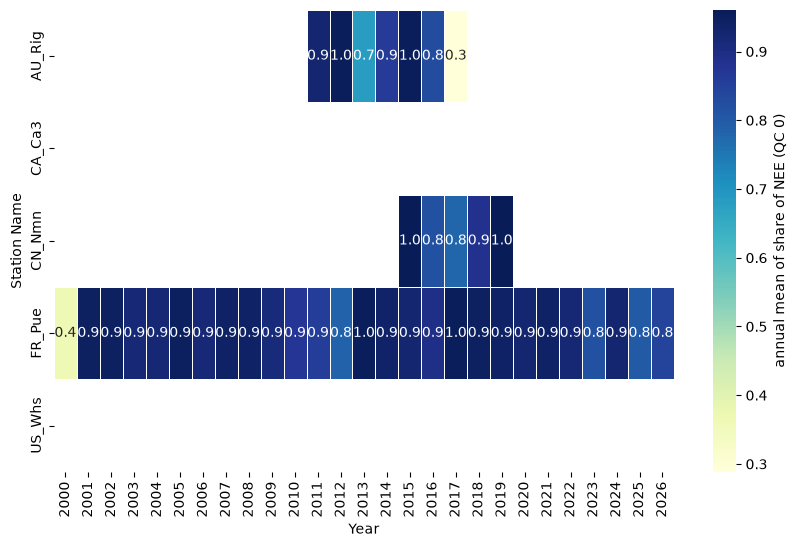

In [35]:
# ---- Extract NEE QC values from data and calculate yearly averages ----

NEE_df = pd.DataFrame({
    'timestamp':data_df['TIME_START'],
    'value':data_df['NEE_VUT_MEAN_QC'],
    'station':data_df['station']
})
NEE_df['year'] = NEE_df['timestamp'].dt.year

NEE_avg_df = NEE_df.groupby(['year', 'station'])['value'].mean().reset_index()

# ---- Heat map: re-format and plot data ----

heatmap_data = NEE_avg_df.pivot(index='station', columns='year', values='value')

plt.figure(figsize=(10, 6))
sns.heatmap(heatmap_data, 
            annot=True,       # Show the numbers in the cells
            fmt=".1f",        # Format to 1 decimal place
            cmap="YlGnBu",    # Yellow-Green-Blue color palette
            cbar_kws={'label': 'annual mean of share of NEE (QC 0)'},
            linewidths=.5)

plt.ylabel('Station Name')
plt.xlabel('Year')
plt.show()

----------

## 3\) Summary statistics

Mean, min, max and % missing of TA, SW_IN, VPD, P, NEE, GPP, RECO, H, LE:

In [28]:
# ---- List of variables to be summarized ----
var_list = [
    'TA_F', 'SW_IN_F', 'VPD_F', 'P_F', 'NEE_VUT_REF', 'GPP_DT_VUT_REF', 'GPP_NT_VUT_REF', 'RECO_NT_VUT_REF', 'H_F_MDS', 'LE_F_MDS'
]

# ---- Custom function for % missing ----
def isna_mean(x):
    return x.isna().mean()

# ---- Calculating statistics for variables and sites ----
summary = round(data_df.groupby('station')[var_list].agg(['mean', 'min', 'max', isna_mean]), 2)

summary.columns = [f"{var}_{stat}" for var, stat in summary.columns]

print(summary)

         TA_F_mean  TA_F_min  TA_F_max  TA_F_isna_mean  SW_IN_F_mean  SW_IN_F_min  SW_IN_F_max  SW_IN_F_isna_mean  VPD_F_mean  VPD_F_min  \
station                                                                                                                                    
AU_Rig       15.67     -2.33     43.08            0.00        199.42          0.0      1237.00               0.00        9.22        0.0   
CA_Ca3        8.22   -307.26     36.39            0.00        138.55          0.0      1127.98               0.00        3.78        0.0   
CN_Nmn        7.71    -31.80     41.32            0.00        181.98          0.0      1135.90               0.00        7.22        0.0   
FR_Pue       14.27     -9.16     42.08            0.01        174.56          0.0      1192.00               0.01        7.03        0.0   
US_Whs       17.87    -14.14     40.29            0.00        247.33          0.0      1352.00               0.00       15.69        0.0   

         ...  RECO_

----------

## 4\) Time series

Daily NEE, GPP and RECO aggregated from the half-hourly data:

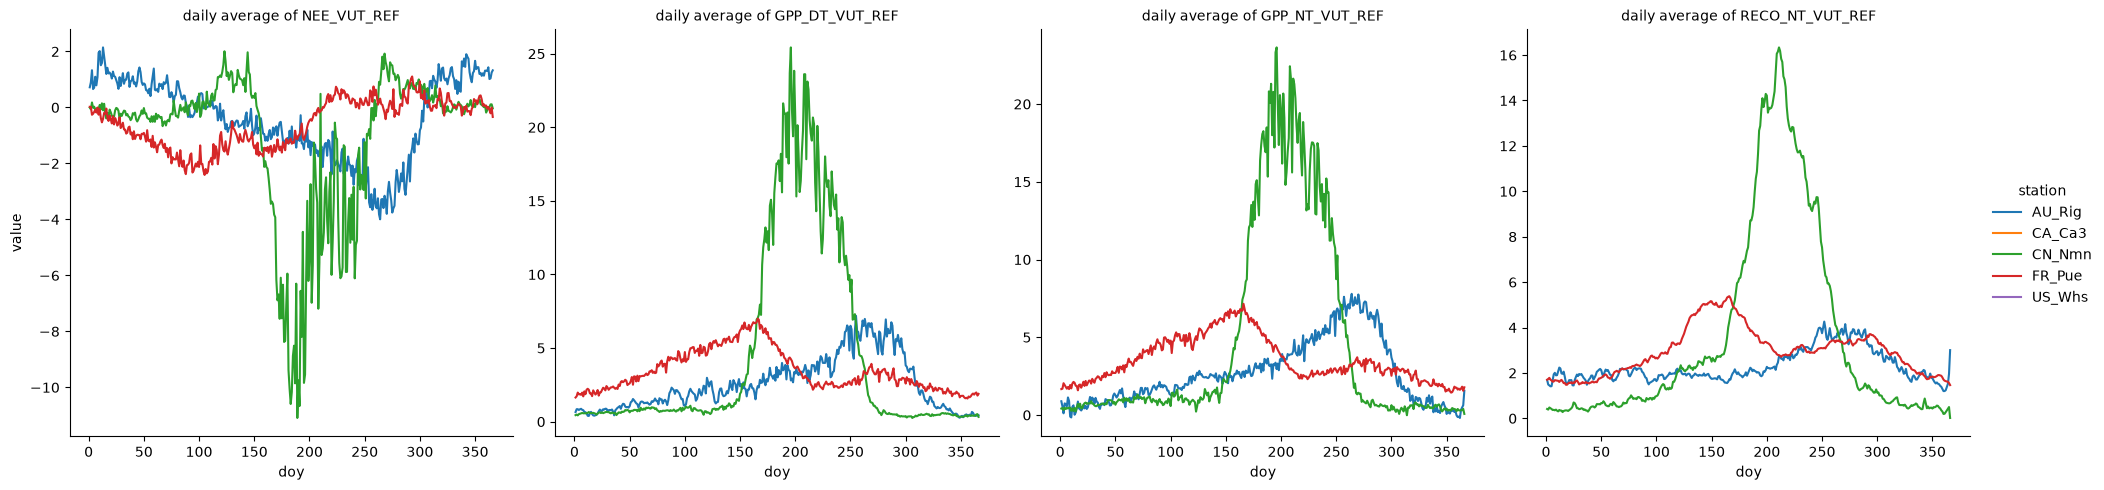

In [ ]:
# ---- Aggregaring over DOY ----
data_df['doy'] = data_df['TIME_START'].dt.day_of_year

var_list = ['NEE_VUT_REF', 'GPP_DT_VUT_REF', 'GPP_NT_VUT_REF', 'RECO_NT_VUT_REF']

time_series = data_df.groupby(['doy', 'station'])[var_list].mean().reset_index()

time_series = pd.melt(
    time_series,
    id_vars=['doy', 'station'],
    var_name='variable',
    value_name='value'
)

# ---- Subplot for every variable ----
g = sns.relplot(
    data=time_series, x='doy', y='value', 
    hue='station', col='variable', # One subplot per variable
    kind='line', facet_kws={'sharey': False} # Each plot gets its own Y-axis scale
)

g.set_titles('daily average of {col_name}')

plt.show()

----------

## 5\) Diurnal cycles

Mean daily course of NEE and LE per season, all five sites:

<positron-console-cell-31>:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-31>:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`


[]

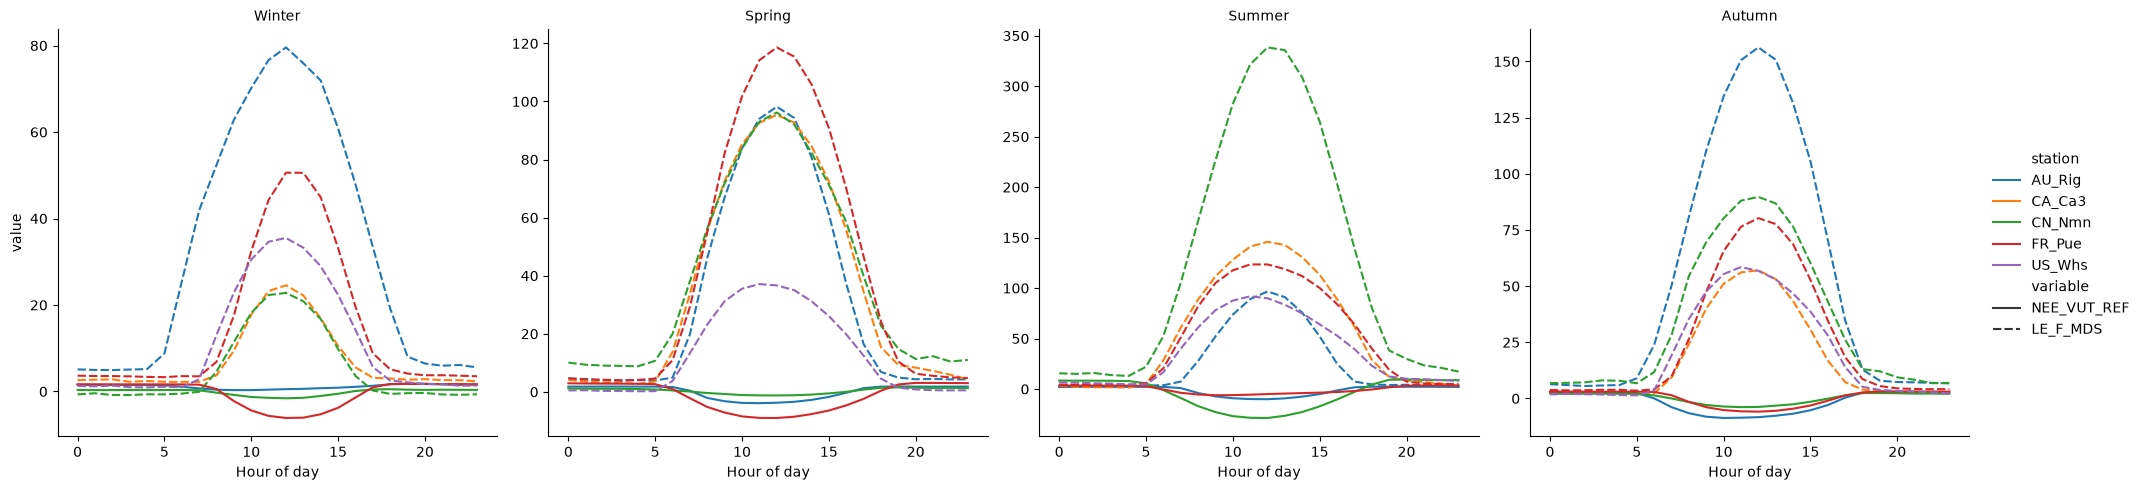

In [31]:
def get_season(doy):
    if 1 <= doy <= 59:      # Jan, Feb
        return 'Winter'
    elif 60 <= doy <= 151:  # Mar, Apr, May
        return 'Spring'
    elif 152 <= doy <= 243: # Jun, Jul, Aug
        return 'Summer'
    elif 244 <= doy <= 334: # Sep, Oct, Nov
        return 'Autumn'
    else:                   # Dec
        return 'Winter'

data_df['season'] = data_df['doy'].apply(get_season)
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
data_df['season'] = pd.Categorical(data_df['season'], categories=season_order, ordered=True)
data_df['hour'] = data_df['TIME_START'].dt.hour

var_list = ['NEE_VUT_REF', 'LE_F_MDS']

diurnal_cycles = data_df.groupby(['station', 'hour', 'season'])[var_list].mean().reset_index()
diurnal_cycles = pd.melt(
    diurnal_cycles,
    id_vars=['station', 'hour', 'season'],
    var_name='variable',
    value_name='value'
)

g = sns.relplot(
    data=diurnal_cycles, x='hour', y='value',
    hue='station', col='season', style='variable',
    kind='line', facet_kws={'sharey': False}
)

g.set_titles('{col_name}')
g.set_xlabels('Hour of day')

plt.plot()

----------

## 6\) My reading

Energy balance plot for one site and 5–8 sentences comparing the towers:

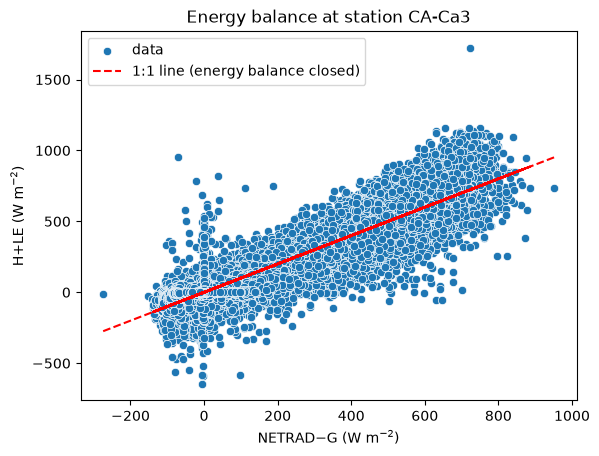

In [21]:
H_LE = data_df['H_CORR'][data_df['station']=='CA_Ca3'] + data_df['LE_CORR'][data_df['station']=='CA_Ca3']
NETRAD_G = data_df['NETRAD'][data_df['station']=='CA_Ca3'] - data_df['G_F_MDS_QC'][data_df['station']=='CA_Ca3']

sns.scatterplot(
    x=list(NETRAD_G),
    y=list(H_LE),
    label='data'
)

plt.plot(NETRAD_G, NETRAD_G, color='red', linestyle='--', label='1:1 line (energy balance closed)')

plt.xlabel('NETRAD$-$G ($\\rm W~m^{-2}$)')
plt.ylabel('H$+$LE ($\\rm W~m^{-2}$)')
plt.title('Energy balance at station CA-Ca3')
plt.legend()
plt.show()

My observations:
- **general data properties**: the towers have very different time ranges, making a direct comparison difficult
- **mean annual NEE QC**: the annual mean of the NEE QC is mostly near 1; however at several stations, only a very limited time range of data is available; at FR-Pue and AU-Rig, there is one year each with a fairly low annual mean of the NEE QC (0.4 and 0.3, respectively)
- **time series**: the station CN-Nmn is very different from all the others; AU-Rig as the only station on the southern hemisphere isn't notably different; unfortunately, due to a lack of data, the stations cannot be compared well
- **diurnal cycles** (*LE*): in this case, the difference for AU-Rig becomes obvious during the northern hemisphere spring and summer (note: the seasons displayed are for the northern hemisphere and therefore not correct for AU-Rig); during summer, there is an immense difference between CN-Nmn and all other stations
- **energy balance plot**: for the selected station (CA-Ca3), the energy balance seems to follow a 1:1 relation overall (however with large deviations in either direction ($\pm 200$)) 